# 03 – Classification : la machine va-t-elle tomber en panne ?

**Objectif :** prédire `failure` (0 = normal, 1 = panne) à partir des mesures des capteurs (jeu AI4I 2020).

**Entrées :** `data/processed/train.csv` et `test.csv` (créés par `01_pretraitement.ipynb`).
**Sorties :** modèles dans `models/`, tableau dans `reports/tables/`, figures dans `reports/figures/`.

⚠️ Seulement ~3,4 % de pannes : l'**accuracy est trompeuse** (un modèle qui dit toujours « normal » aurait 96,6 %). On utilise **PR-AUC, recall, précision et F1**.

#### Étape 1 : importer les bibliothèques

In [1]:
%pip install joblib scikit-learn xgboost matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score,
                             precision_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)
from xgboost import XGBClassifier

SEED = 42
Path("../models").mkdir(exist_ok=True)
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
Path("../reports/tables").mkdir(parents=True, exist_ok=True)

#### Étape 2 : charger les données

In [3]:
train = pd.read_csv("../data/processed/train.csv")
test  = pd.read_csv("../data/processed/test.csv")
print("Train :", train.shape, "| Test :", test.shape)
train.head()

Train : (8000, 11) | Test : (2000, 11)


,Type,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power_w,wear_torque,failure,failure_type
0,2.240505,-0.653287,-0.340471,-0.473000,0.034322,0.003889,0.801938,-0.130678,0.016888,0,Normal
1,-0.740129,-0.703358,-0.205313,0.495232,-0.665740,-0.137809,1.102323,-0.557647,-0.357533,0,Normal
2,0.750188,0.247988,1.011106,-0.890341,0.814391,-0.405461,1.002195,0.625278,-0.128685,0,Normal
3,-0.740129,-1.204067,-1.354153,-1.558088,1.734473,0.491960,0.401426,1.192323,1.298056,0,Normal
4,2.240505,-1.354279,-1.151417,2.209114,-2.075866,-1.318626,1.002195,-2.222299,-1.365132,0,Normal


#### Étape 3 : séparer X et y

On enlève `failure` (la réponse) **et** `failure_type` (elle révèle la réponse : « Normal » = pas de panne). La garder serait une **fuite de données**.

In [4]:
cibles = ["failure", "failure_type"]
X_train = train.drop(columns=cibles)
y_train = train["failure"]
X_test  = test.drop(columns=cibles)
y_test  = test["failure"]

print("Variables utilisées :", list(X_train.columns))
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Pannes dans train : {:.2f} %  -> une panne pour {:.0f} cas normaux".format(100 * y_train.mean(), ratio))

Variables utilisées : ['Type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'temp_diff', 'power_w', 'wear_torque']
Pannes dans train : 3.39 %  -> une panne pour 29 cas normaux


#### Étape 4 : fonction d'évaluation

- **PR-AUC** : qualité globale pour une classe rare (plus c'est proche de 1, mieux c'est).
- **Recall** : parmi les vraies pannes, combien on en détecte (rater une panne coûte cher).
- **Précision** : parmi les alertes, combien sont de vraies pannes (fausse alerte = intervention inutile).
- **F1** : compromis entre recall et précision.

In [5]:
resultats = []

def evaluer(nom, modele, seuil=0.5):
    proba = modele.predict_proba(X_test)[:, 1]
    pred = (proba >= seuil).astype(int)
    ligne = {
        "Modèle": nom,
        "PR-AUC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Recall": recall_score(y_test, pred),
        "Précision": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred),
    }
    resultats.append(ligne)
    return proba, pred

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_pr_auc(modele):
    # PR-AUC moyenne sur 5 découpages du TRAIN : montre si le résultat est stable
    s = cross_val_score(modele, X_train, y_train, cv=cv, scoring="average_precision")
    return s.mean(), s.std()

#### Étape 5 : modèle 1 – régression logistique (modèle de référence)

Simple et rapide : sert de point de comparaison. `class_weight="balanced"` donne plus d'importance aux pannes (rares).

In [6]:
logreg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
cv_m, cv_s = cv_pr_auc(logreg)
print("PR-AUC en validation croisée (train) : {:.3f} ± {:.3f}".format(cv_m, cv_s))

logreg.fit(X_train, y_train)
proba_lr, pred_lr = evaluer("Régression logistique", logreg)
pd.DataFrame(resultats).round(3)

PR-AUC en validation croisée (train) : 0.469 ± 0.036


,Modèle,PR-AUC,ROC-AUC,Recall,Précision,F1
0,Régression logistique,0.403,0.932,0.838,0.17,0.283


#### Étape 6 : modèle 2 – Random Forest

Plusieurs arbres de décision qui votent. Capture les relations non linéaires (ex. usure × couple).

In [7]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                            min_samples_leaf=2, n_jobs=-1, random_state=SEED)
cv_m, cv_s = cv_pr_auc(rf)
print("PR-AUC en validation croisée (train) : {:.3f} ± {:.3f}".format(cv_m, cv_s))

rf.fit(X_train, y_train)
proba_rf, pred_rf = evaluer("Random Forest", rf)
pd.DataFrame(resultats).round(3)

PR-AUC en validation croisée (train) : 0.895 ± 0.021


,Modèle,PR-AUC,ROC-AUC,Recall,Précision,F1
0,Régression logistique,0.403,0.932,0.838,0.170,0.283
1,Random Forest,0.899,0.987,0.838,0.983,0.905


#### Étape 7 : modèle 3 – XGBoost

Arbres construits l'un après l'autre, chacun corrige les erreurs du précédent. `scale_pos_weight` = poids des pannes (rapport normal / panne).

In [8]:
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    random_state=SEED, n_jobs=-1)
cv_m, cv_s = cv_pr_auc(xgb)
print("PR-AUC en validation croisée (train) : {:.3f} ± {:.3f}".format(cv_m, cv_s))

xgb.fit(X_train, y_train)
proba_xgb, pred_xgb = evaluer("XGBoost", xgb)
pd.DataFrame(resultats).round(3)

PR-AUC en validation croisée (train) : 0.860 ± 0.028


,Modèle,PR-AUC,ROC-AUC,Recall,Précision,F1
0,Régression logistique,0.403,0.932,0.838,0.170,0.283
1,Random Forest,0.899,0.987,0.838,0.983,0.905
2,XGBoost,0.861,0.989,0.853,0.716,0.779


#### Étape 8 : tableau final (à recopier dans la section « Résultats » du README)

In [9]:
tableau = pd.DataFrame(resultats).set_index("Modèle").round(3)
tableau.to_csv("../reports/tables/resultats_classification.csv")
tableau

,PR-AUC,ROC-AUC,Recall,Précision,F1
Modèle,,,,,
Régression logistique,0.403,0.932,0.838,0.170,0.283
Random Forest,0.899,0.987,0.838,0.983,0.905
XGBoost,0.861,0.989,0.853,0.716,0.779


#### Étape 9 : courbes précision-rappel

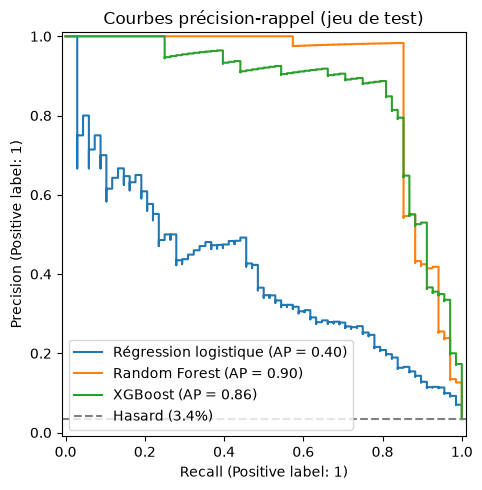

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
for nom, proba in [("Régression logistique", proba_lr), ("Random Forest", proba_rf), ("XGBoost", proba_xgb)]:
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=nom, ax=ax)
ax.axhline(y_test.mean(), color="gray", ls="--", label="Hasard ({:.1%})".format(y_test.mean()))
ax.set_title("Courbes précision-rappel (jeu de test)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/pr_curves.png", dpi=150)
plt.show()

#### Étape 10 : matrices de confusion

Lecture : en bas à gauche = pannes **ratées** (faux négatifs), en haut à droite = **fausses alertes** (faux positifs).

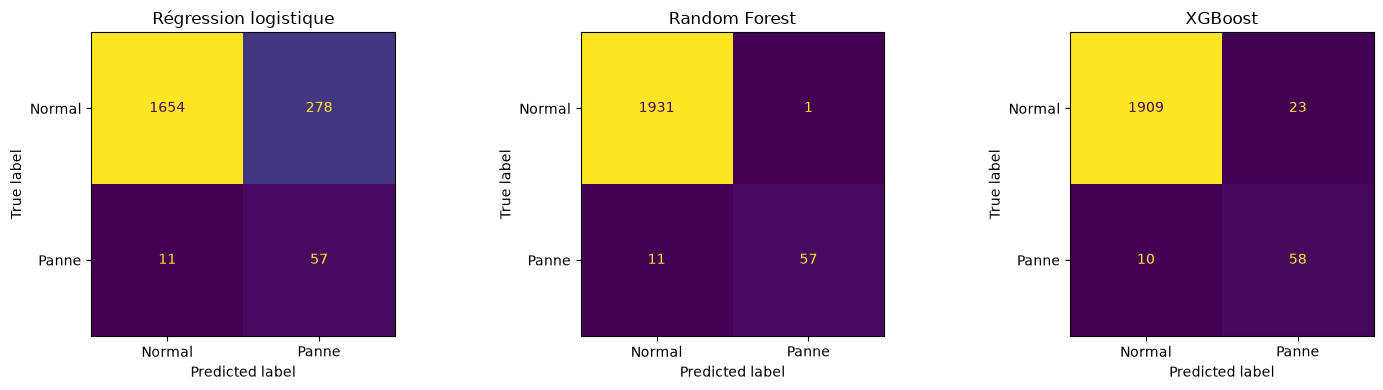

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, pred) in zip(axes, [("Régression logistique", pred_lr), ("Random Forest", pred_rf), ("XGBoost", pred_xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Normal", "Panne"]).plot(ax=ax, colorbar=False)
    ax.set_title(nom)
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrices.png", dpi=150)
plt.show()

#### Étape 11 : quelles variables comptent le plus ? (Random Forest)

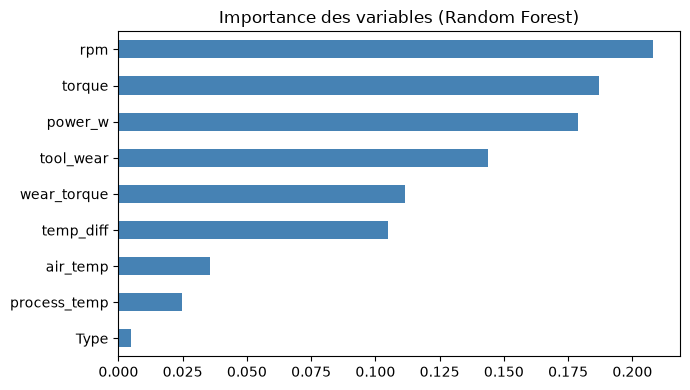

In [12]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.title("Importance des variables (Random Forest)")
plt.tight_layout()
plt.savefig("../reports/figures/feature_importance_rf.png", dpi=150)
plt.show()

#### Étape 12 : sauvegarder les modèles

Note : `.gitignore` contient `models/*.pkl`, donc ces fichiers ne seront pas envoyés sur GitHub (normal, ils se régénèrent avec ce notebook).

In [13]:
joblib.dump(logreg, "../models/logreg.pkl")
joblib.dump(rf, "../models/random_forest.pkl")
joblib.dump(xgb, "../models/xgboost.pkl")
print("Modèles sauvegardés dans models/")

Modèles sauvegardés dans models/


#### À retenir pour le rapport

- Dans AI4I, les pannes sont **générées par des règles** (écart de température, puissance, usure × couple). Les variables `temp_diff`, `power_w` et `wear_torque` les capturent presque directement : des scores très élevés sont donc **normaux** et ne prouvent pas que ce sera aussi facile sur de vraies machines.
- Le seuil de 0,5 est un choix par défaut. L'étape « coût métier » du projet servira à choisir un seuil selon le coût d'une panne ratée vs. d'une fausse alerte.
- Prochaine étape : modèles de survie (`05_survie.ipynb`) sur les données synthétiques.